# 78 · Diffusion Policy on TableTop: 1-D temporal U-Net + FiLM, DDPM training, DDIM sampling

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, show_video
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import DiffusionPolicy, train_policy, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)
H = 16

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
net = DiffusionPolicy(horizon=H)
print(f"Diffusion Policy parameters: {sum(p.numel() for p in net.parameters()) / 1e6:.1f}M (U-Net {sum(p.numel() for p in net.unet.parameters()) / 1e6:.1f}M)")
if os.path.exists("checkpoints/diffusion.pt"):
    net.load_state_dict(torch.load("checkpoints/diffusion.pt", map_location=device)); net.to(device)
else:
    t0 = time.time(); losses = train_policy(net, ds, epochs=60, lr=1e-4, device=device, log_every=5)
    torch.save(net.state_dict(), "checkpoints/diffusion.pt"); print(f"trained in {time.time() - t0:.0f}s")
    plt.figure(figsize=(7, 3.5)); plt.semilogy(np.convolve(losses, np.ones(100) / 100, "valid")); plt.ylabel("ε-prediction MSE"); plt.xlabel("step"); plt.show()

Diffusion Policy parameters: 6.6M (U-Net 5.9M)


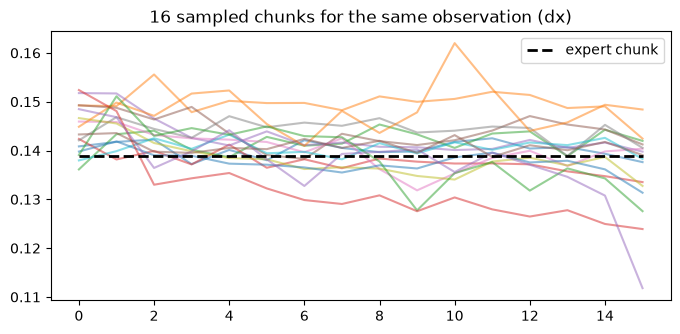

In [3]:
net.eval()
b = {k: v[None].repeat(16, *[1] * v.dim()).to(device) for k, v in ds[1200].items() if k != "pad_mask"}
samples = net.sample(b, nfe=10).cpu().numpy()
plt.figure(figsize=(8, 3.5))
for s in samples:
    plt.plot(s[:, 0], alpha=0.5)
plt.plot(b["action"][0, :, 0].cpu(), "k--", lw=2, label="expert chunk"); plt.legend(); plt.title("16 sampled chunks for the same observation (dx)"); plt.show()

In [4]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
pol = ChunkPolicy(net, ds, env, device, execute=8, nfe=10)
t0 = time.time()
r = evaluate(env, pol, n_episodes=50, seed=50_000, record=2)
print(f"Diffusion Policy (DDIM 10 steps, execute 8 of 16): success {r['success']:.2f} CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}] per task {r['per_task']} ({time.time() - t0:.0f}s)")
from vlacourse import showcase as sc
sc.watch(env, pol, seeds=[50_000 + i for i in range(4)], title="78 Diffusion Policy rollouts")

Diffusion Policy (DDIM 10 steps, execute 8 of 16): success 1.00 CI [0.93, 1.00] per task {'pick': 1.0, 'place': 1.0} (47s)


78 Diffusion Policy rollouts: 4/4 successful


[True, True, True, True]